# 08 - Label Efficiency (RQ4)

Trains the video classifier on increasing fractions of the training labels (10%, 25%, 50%, 100%) and evaluates each on the **same held-out test set**. The resulting accuracy-vs-labels curve shows **how few labels are needed** to reach near-full performance - the label-efficiency evidence for RQ4.

Note: this re-trains the model a few times, so it is the longest notebook (~45-75 min on local data). Saves the curve + metrics to `model23`.

In [1]:
import torch, os
assert torch.cuda.is_available(), 'No GPU active. Runtime > Change runtime type > L4 GPU, then re-run.'
print('GPU:', torch.cuda.get_device_name(0))
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
print('Drive ready:', os.path.isdir('/content/drive/MyDrive'))
!pip install -q opencv-python-headless gdown

GPU: NVIDIA L4
Drive ready: True


In [2]:
CLASSES = [
    (0, 'Short Serve', '00_Short Serve'),
    (1, 'Lift',        '02_Lift'),
    (2, 'Clear',       '12_Clear'),
    (3, 'Drop Shot',   '05_Drop Shot'),
    (4, 'Smash',       '14_Smash'),
]
NUM_CLASSES   = len(CLASSES)
DISPLAY_NAMES = [c[1] for c in CLASSES]
CLASS_FOLDERS = [c[2] for c in CLASSES]
FOLDER_TO_ID  = {c[2]: c[0] for c in CLASSES}
ID_TO_NAME    = {c[0]: c[1] for c in CLASSES}

DRIVE       = '/content/drive/MyDrive/BadmintonFYP'
MODELS      = DRIVE + '/model23'
GDRIVE_FILE_ID = ''
EXTRACT_DIR = '/content/data'

NUM_FRAMES = 16
IMG        = 224
BATCH      = 8
LR         = 1e-4
SEED       = 42
FRACTIONS   = [0.1, 0.25, 0.5, 1.0]
EPOCHS_EACH = 8
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

import os
os.makedirs(MODELS, exist_ok=True)
print('Fractions:', FRACTIONS, '| epochs each:', EPOCHS_EACH)

Fractions: [0.1, 0.25, 0.5, 1.0] | epochs each: 8


In [3]:
import os, json, glob, zipfile, shutil, copy
import cv2, numpy as np, pandas as pd
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms as transforms
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

def has_all(d):
    return os.path.isdir(d) and all(os.path.isdir(os.path.join(d, f)) for f in CLASS_FOLDERS)
def find_root(base):
    for c in [base] + sorted(glob.glob(base + '/*')) + sorted(glob.glob(base + '/*/*')):
        if os.path.isdir(c) and any(os.path.isdir(os.path.join(c, f)) for f in CLASS_FOLDERS):
            return c
    return None
root = find_root(EXTRACT_DIR)
if root is None or not has_all(root):
    zips = [z for p in (DRIVE + '/*.zip', '/content/drive/MyDrive/*.zip', '/content/*.zip') for z in glob.glob(p)]
    zips = [z for z in zips if os.path.exists(z)]
    if not zips:
        import gdown
        outp = '/content/DATASET2.zip'
        if not os.path.exists(outp):
            gdown.download(id=GDRIVE_FILE_ID, output=outp, quiet=False)
        if os.path.exists(outp) and os.path.getsize(outp) > 1000000:
            zips = [outp]
    if zips:
        if os.path.exists(EXTRACT_DIR): shutil.rmtree(EXTRACT_DIR)
        with zipfile.ZipFile(zips[0]) as z: z.extractall(EXTRACT_DIR)
        root = find_root(EXTRACT_DIR)
DATASET_DIR = root or EXTRACT_DIR
print('DATASET_DIR =', DATASET_DIR)

class TemporalPoolingResNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        w = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        base = models.resnet18(weights=w)
        self.features = nn.Sequential(*list(base.children())[:-1])
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.view(b*t, c, h, w)
        x = self.features(x).view(b, t, 512).mean(dim=1)
        return self.fc(x)

_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
def load_frames(path, n=NUM_FRAMES):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened(): raise ValueError('cannot open ' + path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0: cap.release(); raise ValueError('0 frames')
    frames = []
    for i in np.linspace(0, total-1, n, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, fr = cap.read()
        if ok: frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        elif frames: frames.append(frames[-1].copy())
    cap.release()
    while len(frames) < n: frames.append(frames[-1].copy() if frames else np.zeros((IMG,IMG,3),np.uint8))
    return frames[:n]
def letterbox(img, size=IMG):
    h, w = img.shape[:2]; s = min(size/h, size/w); nh, nw = int(h*s), int(w*s)
    r = cv2.resize(img, (nw, nh)); c = np.zeros((size,size,3),np.uint8); y, x = (size-nh)//2, (size-nw)//2; c[y:y+nh, x:x+nw] = r; return c
class VideoClipDataset(Dataset):
    def __init__(self, df): self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        try:
            fr = load_frames(row.file_path)
            t = torch.stack([_norm(torch.from_numpy(letterbox(f).astype(np.float32)/255.0).permute(2,0,1)) for f in fr])
            return t, int(row.label_id)
        except Exception:
            return torch.zeros(NUM_FRAMES,3,IMG,IMG), int(row.label_id)
def build_index(rootdir):
    rows = []
    for folder in CLASS_FOLDERS:
        p = os.path.join(rootdir, folder)
        if not os.path.isdir(p): continue
        lid = FOLDER_TO_ID[folder]
        for fn in os.listdir(p):
            if fn.lower().endswith('.mp4'):
                gid = fn.split('_dataset_set')[0] if '_dataset_set' in fn else fn[:19]
                rows.append({'file_path': os.path.join(p, fn), 'label_id': lid, 'group_id': gid})
    return pd.DataFrame(rows)
def group_split(df, val=0.15, test=0.15, seed=SEED):
    g1 = GroupShuffleSplit(n_splits=1, test_size=val+test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.group_id))
    dtmp = df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test/(val+test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.group_id))
    return df.iloc[tr].reset_index(drop=True), dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)
def class_weights(d):
    cnt = d.label_id.value_counts().sort_index(); tot = len(d)
    return torch.tensor([tot / (NUM_CLASSES * cnt.get(i, 1)) for i in range(NUM_CLASSES)], dtype=torch.float32)
def run_epoch(m, loader, crit, opt=None):
    train = opt is not None
    m.train() if train else m.eval()
    P, L = [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if train: opt.zero_grad()
            out = m(x); loss = crit(out, y)
            if train: loss.backward(); opt.step()
            P += out.argmax(1).cpu().tolist(); L += y.cpu().tolist()
    return accuracy_score(L, P), f1_score(L, P, average='macro')

df_train, df_val, df_test = group_split(build_index(DATASET_DIR))
print('train', len(df_train), 'val', len(df_val), 'test', len(df_test))

Device: cuda
DATASET_DIR = /content/data
train 2828 val 658 test 732


In [4]:
val_loader  = DataLoader(VideoClipDataset(df_val),  batch_size=BATCH, num_workers=2)
test_loader = DataLoader(VideoClipDataset(df_test), batch_size=BATCH, num_workers=2)
results = []

for f in FRACTIONS:
    if f < 1.0:
        sub = df_train.groupby('label_id', group_keys=False).sample(frac=f, random_state=SEED).reset_index(drop=True)
    else:
        sub = df_train
    print('=== %d%% of labels -> %d train clips ===' % (int(f*100), len(sub)))
    tr_loader = DataLoader(VideoClipDataset(sub), batch_size=BATCH, shuffle=True, num_workers=2)
    m = TemporalPoolingResNet(pretrained=True).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=class_weights(sub).to(DEVICE))
    opt = optim.Adam(m.parameters(), lr=LR)
    best_f1, best_state, bad = 0.0, None, 0
    for ep in range(EPOCHS_EACH):
        run_epoch(m, tr_loader, crit, opt)
        va, vf = run_epoch(m, val_loader, crit)
        if vf > best_f1:
            best_f1, best_state, bad = vf, copy.deepcopy(m.state_dict()), 0
        else:
            bad += 1
            if bad >= 3: break
    m.load_state_dict(best_state)
    t_acc, t_f1 = run_epoch(m, test_loader, crit)
    print('  -> test acc %.3f | macro-F1 %.3f' % (t_acc, t_f1))
    results.append({'fraction': f, 'n_clips': int(len(sub)), 'test_acc': float(t_acc), 'test_f1': float(t_f1)})
    del m; torch.cuda.empty_cache()

print('\nLabel-efficiency results:')
for r in results:
    print('  %3d%% (%4d clips): acc %.3f  macro-F1 %.3f' % (int(r['fraction']*100), r['n_clips'], r['test_acc'], r['test_f1']))

=== 10% of labels -> 282 train clips ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 238MB/s]


  -> test acc 0.709 | macro-F1 0.714
=== 25% of labels -> 707 train clips ===
  -> test acc 0.796 | macro-F1 0.797
=== 50% of labels -> 1414 train clips ===
  -> test acc 0.887 | macro-F1 0.877
=== 100% of labels -> 2828 train clips ===
  -> test acc 0.943 | macro-F1 0.937

Label-efficiency results:
   10% ( 282 clips): acc 0.709  macro-F1 0.714
   25% ( 707 clips): acc 0.796  macro-F1 0.797
   50% (1414 clips): acc 0.887  macro-F1 0.877
  100% (2828 clips): acc 0.943  macro-F1 0.937


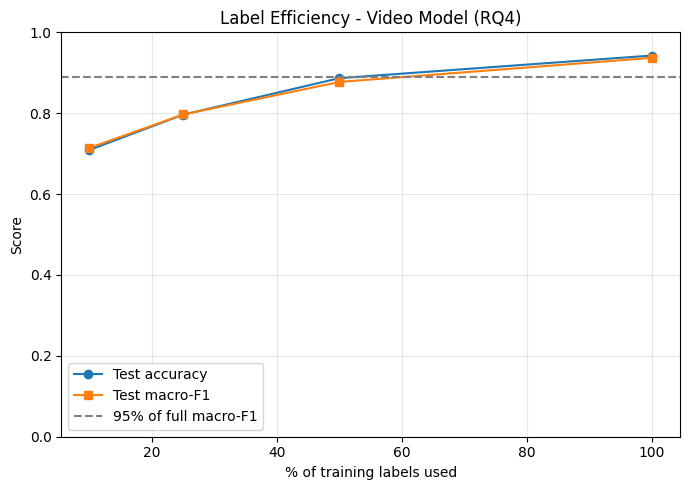

Full-data macro-F1: 0.937
Reaches 95% of it with as little as 100% of the labels.
Saved label-efficiency curve + metrics to /content/drive/MyDrive/BadmintonFYP/model23


In [5]:
xs  = [r['fraction']*100 for r in results]
acc = [r['test_acc'] for r in results]
f1  = [r['test_f1'] for r in results]

plt.figure(figsize=(7, 5))
plt.plot(xs, acc, 'o-', color='C0', label='Test accuracy')
plt.plot(xs, f1, 's-', color='C1', label='Test macro-F1')
full = f1[-1]
plt.axhline(0.95*full, ls='--', color='gray', label='95% of full macro-F1')
plt.xlabel('% of training labels used'); plt.ylabel('Score'); plt.ylim(0, 1)
plt.title('Label Efficiency - Video Model (RQ4)'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(MODELS + '/label_efficiency.png', dpi=150); plt.show()

reach = next((r['fraction'] for r in results if r['test_f1'] >= 0.95*full), 1.0)
print('Full-data macro-F1: %.3f' % full)
print('Reaches 95%% of it with as little as %d%% of the labels.' % int(reach*100))
json.dump({'results': results, 'full_macro_f1': full, 'frac_for_95pct': reach},
          open(MODELS + '/label_efficiency.json', 'w'), indent=2)
print('Saved label-efficiency curve + metrics to', MODELS)